# FER project: dataset audit and measured ML results

This notebook reads the project’s saved data audits and experiment artifacts. It performs no download and does not retrain a model. It separates the original FER2013 labels from Microsoft FER+ consensus labels so the two evaluation targets are not confused.

The MLP results below are the earlier FER+ baseline. The active CNN architecture, comparison, and current PrivateTest results are in `03_cnn_layers_results.ipynb`.

Run top to bottom with the **facial_emotion_ai** Anaconda kernel.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'config.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'config.py').exists():
    ROOT = Path.home() / 'Desktop' / 'facial-emotion-recognition'
if not (ROOT / 'src' / 'config.py').exists():
    raise FileNotFoundError('Open this notebook from the Desktop facial-emotion-recognition project.')
RESULTS = ROOT / 'results'
RUNS = RESULTS / 'runs'
print('Project:', ROOT)
print('Notebook kernel:', sys.executable)

Project: .
Notebook kernel: Python (facial_emotion_ai)


## 1. Dataset and FER+ annotation audit

In [2]:
original_csv = ROOT / 'data' / 'raw' / 'fer2013' / 'fer2013.csv'
ferplus_csv = ROOT / 'data' / 'raw' / 'ferplus' / 'fer2013new.csv'
validation_path = ROOT / 'data' / 'metadata' / 'data_validation.json'
validation = json.loads(validation_path.read_text(encoding='utf-8'))
print('FER2013 validation:', validation['rows_seen'], 'rows;', validation['invalid_count'], 'invalid')
print('Split counts:', validation['split_counts'])
if ferplus_csv.exists():
    ferplus = pd.read_csv(ferplus_csv)
    fer_usage = ferplus['Usage'].value_counts().reindex(['Training', 'PublicTest', 'PrivateTest']).fillna(0).astype(int)
    orig_usage = pd.read_csv(original_csv, usecols=['Usage'])['Usage'].value_counts().reindex(fer_usage.index).fillna(0).astype(int)
    display(pd.DataFrame({'FER2013 images': orig_usage, 'FER+ annotation rows': fer_usage}))
    print('Row count and split order align:', len(ferplus) == len(pd.read_csv(original_csv, usecols=['Usage'])) and (ferplus['Usage'].to_numpy() == pd.read_csv(original_csv, usecols=['Usage'])['Usage'].to_numpy()).all())
    print('FER+ adds crowd-sourced votes; it does not add new images.')
else:
    print('FER+ vote annotations have not been imported yet.')

FER2013 validation: 35887 rows; 0 invalid
Split counts: {'Training': 28709, 'PublicTest': 3589, 'PrivateTest': 3589}


,FER2013 images,FER+ annotation rows
Usage,,
Training,28709,28709
PublicTest,3589,3589
PrivateTest,3589,3589


Row count and split order align: True
FER+ adds crowd-sourced votes; it does not add new images.


## 2. Original FER2013 validation results

In [3]:
full_run = RUNS / '20261121T222130Z_full_6297687c'
flip_run = RUNS / '20261121T225141Z_flip_average_64697dee'
comparison = pd.read_csv(full_run / 'validation_comparison.csv')
base_mlp = comparison.loc[comparison['name'] == 'mlp_128_64'].iloc[0]
flip_val = json.loads((flip_run / 'validation_flip_average.json').read_text(encoding='utf-8'))
flip_test = json.loads((flip_run / 'final_test_metrics.json').read_text(encoding='utf-8'))
base_test = json.loads((full_run / 'final_test_metrics.json').read_text(encoding='utf-8'))
original_results = pd.DataFrame([
    {'Model / inference': 'MLP · single face view', 'Split': 'PublicTest', 'Accuracy': base_mlp['accuracy'], 'Macro-F1': base_mlp['macro_f1']},
    {'Model / inference': 'MLP · face + horizontal mirror average', 'Split': 'PublicTest', 'Accuracy': flip_val['accuracy'], 'Macro-F1': flip_val['macro_f1']},
    {'Model / inference': 'MLP · single face view', 'Split': 'PrivateTest', 'Accuracy': base_test['accuracy'], 'Macro-F1': base_test['macro_f1']},
    {'Model / inference': 'MLP · face + horizontal mirror average', 'Split': 'PrivateTest', 'Accuracy': flip_test['accuracy'], 'Macro-F1': flip_test['macro_f1']},
])
display(original_results.style.format({'Accuracy':'{:.2%}', 'Macro-F1':'{:.2%}'}))

,Model / inference,Split,Accuracy,Macro-F1
0,MLP · single face view,PublicTest,40.46%,32.20%
1,MLP · face + horizontal mirror average,PublicTest,40.99%,32.27%
2,MLP · single face view,PrivateTest,39.31%,31.44%
3,MLP · face + horizontal mirror average,PrivateTest,39.79%,31.78%


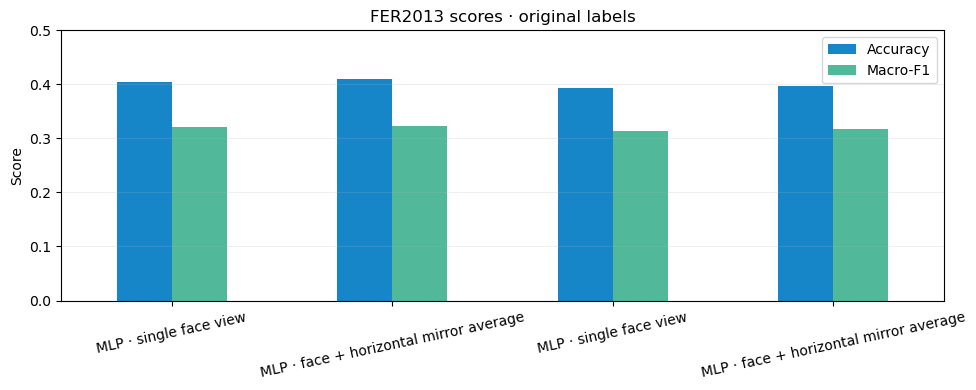

In [4]:
ax = original_results.plot(x='Model / inference', y=['Accuracy', 'Macro-F1'], kind='bar', figsize=(10, 4), ylim=(0, 0.5), color=['#1786c8', '#51b99a'])
ax.set_title('FER2013 scores · original labels')
ax.set_ylabel('Score')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=12)
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

## 3. FER+ consensus-label experiment

In [5]:
ferplus_runs = sorted(RUNS.glob('*_ferplus_majority_*'), key=lambda p: p.name)
ferplus_run = ferplus_runs[-1] if ferplus_runs else None
if ferplus_run and (ferplus_run / 'ferplus_data_audit.json').exists():
    audit = json.loads((ferplus_run / 'ferplus_data_audit.json').read_text(encoding='utf-8'))
    display(pd.DataFrame(audit['counts']).T.rename_axis('Split'))
    baseline_consensus = json.loads((ferplus_run / 'validation_baseline_on_ferplus_consensus.json').read_text(encoding='utf-8'))
    candidate_consensus = json.loads((ferplus_run / 'validation_candidate_on_ferplus_consensus.json').read_text(encoding='utf-8'))
    consensus_results = pd.DataFrame([
        {'Model': 'Existing MLP, evaluated on FER+ consensus', 'Split': 'PublicTest consensus', 'Accuracy': baseline_consensus['accuracy'], 'Macro-F1': baseline_consensus['macro_f1']},
        {'Model': 'MLP trained on FER+ consensus labels', 'Split': 'PublicTest consensus', 'Accuracy': candidate_consensus['accuracy'], 'Macro-F1': candidate_consensus['macro_f1']},
    ])
    display(consensus_results.style.format({'Accuracy':'{:.2%}', 'Macro-F1':'{:.2%}'}))
    ferplus_test_path = ferplus_run / 'final_test_metrics_ferplus_consensus.json'
    if ferplus_test_path.exists():
        ferplus_test = json.loads(ferplus_test_path.read_text(encoding='utf-8'))
        display(pd.DataFrame([{'Model': 'Selected FER+ MLP + mirror average', 'Split': 'PrivateTest consensus', 'Accuracy': ferplus_test['accuracy'], 'Macro-F1': ferplus_test['macro_f1']}]).style.format({'Accuracy':'{:.2%}', 'Macro-F1':'{:.2%}'}))
    else:
        print('FER+ model was not promoted on validation; the private test was not evaluated.')
else:
    print('FER+ training experiment has not been run yet.')

,available,accepted,discarded_ambiguous
Split,,,
Training,28709,26593,2116
PublicTest,3589,3356,233
PrivateTest,3589,3329,260


,Model,Split,Accuracy,Macro-F1
0,"Existing MLP, evaluated on FER+ consensus",PublicTest consensus,42.31%,30.57%
1,MLP trained on FER+ consensus labels,PublicTest consensus,54.98%,36.36%


,Model,Split,Accuracy,Macro-F1
0,Selected FER+ MLP + mirror average,PrivateTest consensus,55.00%,34.14%


## 4. Per-class scores and interpretation

,Class,Original-label F1 · single view,Original-label F1 · mirror average,Support
0,Angry,28.4%,28.3%,491
1,Disgust,0.0%,3.6%,55
2,Fear,17.4%,13.6%,528
3,Happy,57.0%,58.0%,879
4,Sad,28.3%,30.7%,594
5,Surprise,51.9%,51.0%,416
6,Neutral,37.1%,37.4%,626


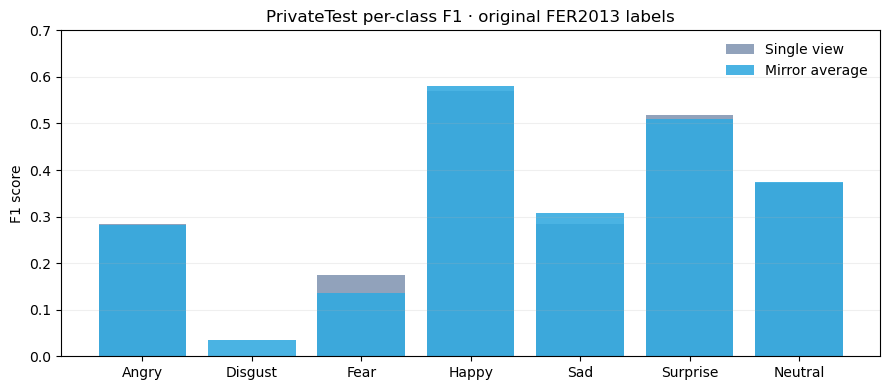

In [6]:
class_names = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
base_report = base_test['classification_report']
flip_report = flip_test['classification_report']
per_class = pd.DataFrame({
    'Class': class_names,
    'Original-label F1 · single view': [base_report[c]['f1-score'] for c in class_names],
    'Original-label F1 · mirror average': [flip_report[c]['f1-score'] for c in class_names],
    'Support': [int(flip_report[c]['support']) for c in class_names],
})
display(per_class.style.format({'Original-label F1 · single view':'{:.1%}', 'Original-label F1 · mirror average':'{:.1%}'}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_names, per_class['Original-label F1 · single view'], label='Single view', color='#91a2bb')
ax.bar(class_names, per_class['Original-label F1 · mirror average'], label='Mirror average', color='#31a9e0', alpha=.88)
ax.set_ylim(0, 0.7)
ax.set_ylabel('F1 score')
ax.set_title('PrivateTest per-class F1 · original FER2013 labels')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

## Evaluation notes

- The mirror-average strategy was chosen using **PublicTest** validation results. FER2013 **PrivateTest** was used only after that choice.
- FER+ is not a larger or more diverse image collection: Microsoft provides more detailed crowd-vote annotations aligned with the same FER2013 rows. The FER+ experiment uses a unique highest vote count among the seven target emotion classes, with at least four votes and excludes ambiguous rows.
- FER2013 and FER+ scores use different ground-truth definitions. Compare the FER+ candidate only to the existing model evaluated on the same FER+ consensus rows.
- This project predicts visible expression labels; it does not measure a person’s internal emotional state.